In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Libraries loaded successfully!")

Libraries loaded successfully!


In [3]:
import os

DATASET_PATH = "../dataset/food-101"

print("Dataset path:", DATASET_PATH)
print("Path exists:", os.path.exists(DATASET_PATH))

print("\nFolders/files:")
print(os.listdir(DATASET_PATH))

Dataset path: ../dataset/food-101
Path exists: True

Folders/files:
['images', 'license_agreement.txt', 'meta', 'README.txt']


In [4]:
classes_path = os.path.join(DATASET_PATH, "meta", "classes.txt")

with open(classes_path, "r") as f:
    classes = [line.strip() for line in f.readlines()]

print("Total Food Classes:", len(classes))
print("\nFirst 10 classes:")
print(classes[:10])

Total Food Classes: 101

First 10 classes:
['apple_pie', 'baby_back_ribs', 'baklava', 'beef_carpaccio', 'beef_tartare', 'beet_salad', 'beignets', 'bibimbap', 'bread_pudding', 'breakfast_burrito']


In [5]:
images_path = os.path.join(DATASET_PATH, "images")

food_folders = os.listdir(images_path)

print("Total food folders:", len(food_folders))
print("\nFirst 10 food folders:")
print(food_folders[:10])

Total food folders: 102

First 10 food folders:
['.DS_Store', 'apple_pie', 'baby_back_ribs', 'baklava', 'beef_carpaccio', 'beef_tartare', 'beet_salad', 'beignets', 'bibimbap', 'bread_pudding']


Food Class: apple_pie
Image Size: (308, 512)


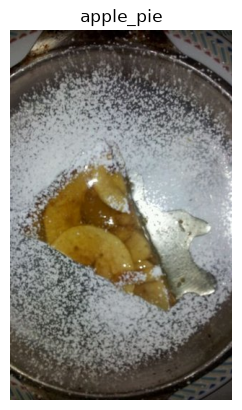

In [6]:
from PIL import Image
import matplotlib.pyplot as plt
import os

sample_class = classes[0]
sample_folder = os.path.join(images_path, sample_class)

sample_image = os.listdir(sample_folder)[0]
image_path = os.path.join(sample_folder, sample_image)

img = Image.open(image_path)

print("Food Class:", sample_class)
print("Image Size:", img.size)

plt.imshow(img)
plt.axis("off")
plt.title(sample_class)
plt.show()

In [7]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import numpy as np
import os

print("TensorFlow:", tf.__version__)
print("Setup successful!")

TensorFlow: 2.21.0
Setup successful!


In [8]:
import tensorflow as tf
import os

DATASET_PATH = "../dataset/food-101"

TRAIN_FILE = os.path.join(DATASET_PATH, "meta", "train.txt")
TEST_FILE = os.path.join(DATASET_PATH, "meta", "test.txt")
IMAGES_PATH = os.path.join(DATASET_PATH, "images")

print("Train file exists:", os.path.exists(TRAIN_FILE))
print("Test file exists:", os.path.exists(TEST_FILE))
print("Images folder exists:", os.path.exists(IMAGES_PATH))

Train file exists: True
Test file exists: True
Images folder exists: True


In [9]:
import os

# Food classes
classes_path = os.path.join(DATASET_PATH, "meta", "classes.txt")

with open(classes_path, "r") as f:
    classes = [line.strip() for line in f.readlines()]

print("Total classes:", len(classes))
print("First 10 classes:", classes[:10])

# Training image list
with open(TRAIN_FILE, "r") as f:
    train_images = [line.strip() for line in f.readlines()]

# Testing image list
with open(TEST_FILE, "r") as f:
    test_images = [line.strip() for line in f.readlines()]

print("Training images:", len(train_images))
print("Testing images:", len(test_images))

Total classes: 101
First 10 classes: ['apple_pie', 'baby_back_ribs', 'baklava', 'beef_carpaccio', 'beef_tartare', 'beet_salad', 'beignets', 'bibimbap', 'bread_pudding', 'breakfast_burrito']
Training images: 75750
Testing images: 25250


In [10]:
from tensorflow.keras.utils import image_dataset_from_directory

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

train_dir = os.path.join(DATASET_PATH, "images")

train_ds = image_dataset_from_directory(
    train_dir,
    labels="inferred",
    label_mode="int",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    validation_split=0.2,
    subset="training",
    seed=42
)

val_ds = image_dataset_from_directory(
    train_dir,
    labels="inferred",
    label_mode="int",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    validation_split=0.2,
    subset="validation",
    seed=42
)

print("Training batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())

Found 101000 files belonging to 101 classes.
Using 80800 files for training.
Found 101000 files belonging to 101 classes.
Using 20200 files for validation.
Training batches: 2525
Validation batches: 632


In [12]:
import sys
!{sys.executable} -m pip install importlib-resources

In [3]:
import os

print("Current folder:")
print(os.getcwd())

Current folder:
c:\Users\krishna\Documents\Python codes\PRODIGY_ML_05\notebook


In [5]:
import os

dataset_path = os.path.join("..", "dataset", "food-101")
images_path = os.path.join(dataset_path, "images")

# Sirf actual folders ko classes maanenge
classes = sorted([
    folder for folder in os.listdir(images_path)
    if os.path.isdir(os.path.join(images_path, folder))
])

print("Total food classes:", len(classes))
print("First 10 classes:", classes[:10])

for food_class in classes[:5]:
    folder = os.path.join(images_path, food_class)
    images = [
        f for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]
    print(food_class, "->", len(images), "images")

Total food classes: 101
First 10 classes: ['apple_pie', 'baby_back_ribs', 'baklava', 'beef_carpaccio', 'beef_tartare', 'beet_salad', 'beignets', 'bibimbap', 'bread_pudding', 'breakfast_burrito']
apple_pie -> 1000 images
baby_back_ribs -> 1000 images
baklava -> 1000 images
beef_carpaccio -> 1000 images
beef_tartare -> 1000 images


In [6]:
import tensorflow as tf
import os

IMG_SIZE = 224
BATCH_SIZE = 32
NUM_CLASSES = 101

data_dir = os.path.join("..", "dataset", "food-101", "images")

train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    label_mode="int"
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    label_mode="int"
)

class_names = train_ds.class_names

print("Number of classes:", len(class_names))
print("First 10 classes:", class_names[:10])

Found 101000 files belonging to 101 classes.
Using 80800 files for training.
Found 101000 files belonging to 101 classes.
Using 20200 files for validation.
Number of classes: 101
First 10 classes: ['apple_pie', 'baby_back_ribs', 'baklava', 'beef_carpaccio', 'beef_tartare', 'beet_salad', 'beignets', 'bibimbap', 'bread_pudding', 'breakfast_burrito']


In [7]:
import tensorflow as tf

# Pretrained EfficientNetB0
base_model = tf.keras.applications.EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3)
)

# Pehle pretrained layers freeze
base_model.trainable = False

model = tf.keras.Sequential([
    base_model,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(101, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 20s 1us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 101)            │       129,381 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,178,952 (15.94 MB)

 Trainable params: 129,381 (505.39 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [8]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)

print("Dataset pipeline ready!")

Dataset pipeline ready!


In [9]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5
)

Epoch 1/5


c:\Users\krishna\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


 507/2525 ━━━━━━━━━━━━━━━━━━━━ 28:06:16 50s/step - accuracy: 0.4058 - loss: 2.6573

KeyboardInterrupt: 

In [2]:
import tensorflow as tf
import os

# -----------------------------
# 1. Dataset
# -----------------------------
IMG_SIZE = 224
BATCH_SIZE = 32
NUM_CLASSES = 101

data_dir = os.path.join("..", "dataset", "food-101", "images")

train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    label_mode="int"
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    label_mode="int"
)

# -----------------------------
# 2. Fast dataset
# -----------------------------
AUTOTUNE = tf.data.AUTOTUNE

FAST_TRAIN_BATCHES = 320
FAST_VAL_BATCHES = 64

fast_train_ds = train_ds.take(FAST_TRAIN_BATCHES).prefetch(AUTOTUNE)
fast_val_ds = val_ds.take(FAST_VAL_BATCHES).prefetch(AUTOTUNE)

print("Fast dataset ready!")

# -----------------------------
# 3. EfficientNetB0
# -----------------------------
base_model = tf.keras.applications.EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3)
)

base_model.trainable = False

model = tf.keras.Sequential([
    base_model,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(NUM_CLASSES, activation="softmax")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model ready!")

Found 101000 files belonging to 101 classes.
Using 80800 files for training.
Found 101000 files belonging to 101 classes.
Using 20200 files for validation.
Fast dataset ready!
Model ready!


In [3]:
history = model.fit(
    fast_train_ds,
    validation_data=fast_val_ds,
    epochs=3
)

Epoch 1/3


c:\Users\krishna\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


320/320 ━━━━━━━━━━━━━━━━━━━━ 323s 961ms/step - accuracy: 0.3439 - loss: 2.9951 - val_accuracy: 0.5269 - val_loss: 2.0936
Epoch 2/3
320/320 ━━━━━━━━━━━━━━━━━━━━ 315s 984ms/step - accuracy: 0.5789 - loss: 1.8070 - val_accuracy: 0.5723 - val_loss: 1.7622
Epoch 3/3
320/320 ━━━━━━━━━━━━━━━━━━━━ 303s 947ms/step - accuracy: 0.6336 - loss: 1.4832 - val_accuracy: 0.5942 - val_loss: 1.6239


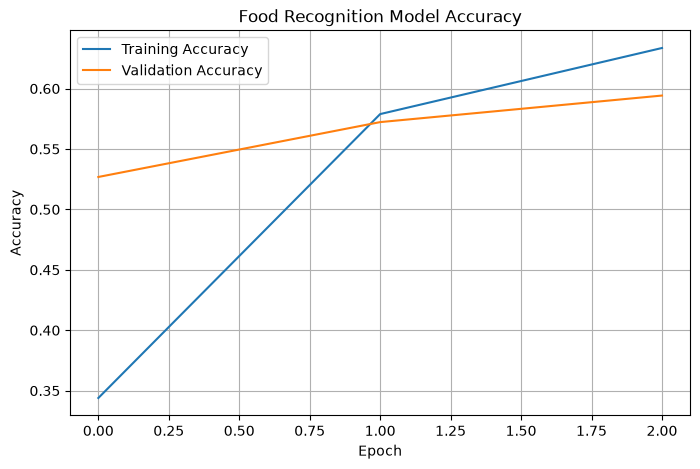

In [4]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("Food Recognition Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.show()

In [5]:
model.save("food_recognition_model.keras")

print("Model saved successfully!")

Model saved successfully!


In [7]:
import os

data_dir = os.path.join("..", "dataset", "food-101", "images")

class_names = sorted([
    folder for folder in os.listdir(data_dir)
    if os.path.isdir(os.path.join(data_dir, folder))
])

print("Total classes:", len(class_names))
print(class_names[:10])

Total classes: 101
['apple_pie', 'baby_back_ribs', 'baklava', 'beef_carpaccio', 'beef_tartare', 'beet_salad', 'beignets', 'bibimbap', 'bread_pudding', 'breakfast_burrito']


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 131ms/step


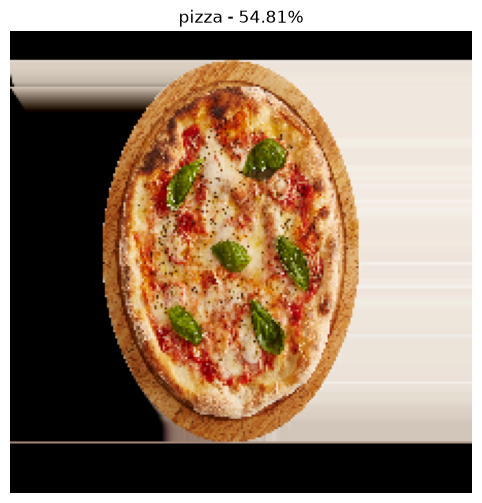

Predicted Food: pizza
Confidence: 54.81%


In [9]:
predictions = model.predict(img_array)

predicted_index = np.argmax(predictions[0])
predicted_class = class_names[predicted_index]
confidence = predictions[0][predicted_index] * 100

plt.figure(figsize=(6, 6))
plt.imshow(img)
plt.axis("off")
plt.title(f"{predicted_class} - {confidence:.2f}%")
plt.show()

print("Predicted Food:", predicted_class)
print(f"Confidence: {confidence:.2f}%")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 123ms/step


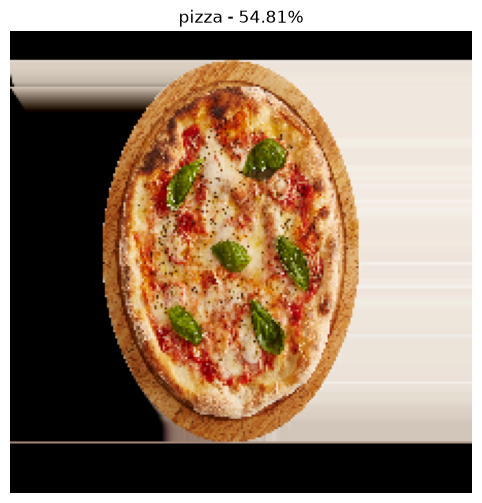

Predicted Food: pizza
Confidence: 54.81%


In [10]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

# Pizza image
image_path = "pizza.jpg"

# Load image
img = tf.keras.utils.load_img(
    image_path,
    target_size=(224, 224)
)

# Convert image to array
img_array = tf.keras.utils.img_to_array(img)
img_array = tf.expand_dims(img_array, 0)

# Predict
predictions = model.predict(img_array)

# Get result
predicted_index = np.argmax(predictions[0])
predicted_class = class_names[predicted_index]
confidence = predictions[0][predicted_index] * 100

# Show image and result
plt.figure(figsize=(6, 6))
plt.imshow(img)
plt.axis("off")
plt.title(f"{predicted_class} - {confidence:.2f}%")
plt.show()

print("Predicted Food:", predicted_class)
print(f"Confidence: {confidence:.2f}%")

In [11]:
model.save("food_recognition_model.keras")
print("Model saved successfully!")

Model saved successfully!


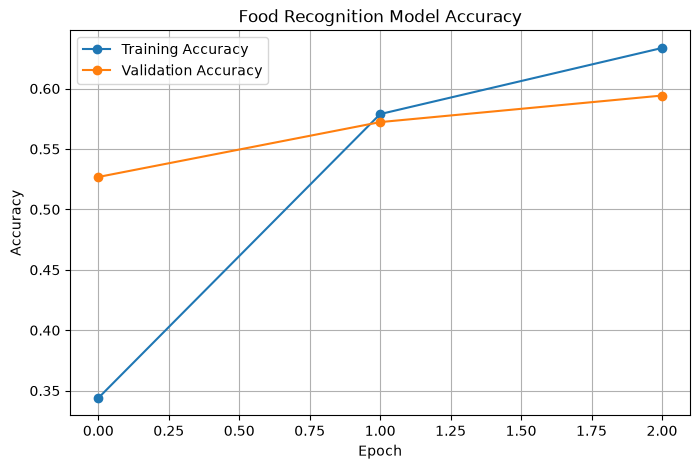

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], marker="o", label="Training Accuracy")
plt.plot(history.history["val_accuracy"], marker="o", label="Validation Accuracy")

plt.title("Food Recognition Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.show()